# Práctica 3 - Clasificación
Introducción a la Ciencia de Datos  
### María Guadalupe Villanueva Utrilla

El objetivo es predecir, al terminar el primer semestre, si cada estudiante terminará como dropout, enrolled o graduate. El conjunto procede del Instituto Politécnico de Portalegre (Portugal), con 4,424 registros originales. El curso proporciona 3,539 estudiantes con etiqueta y 885 sin etiqueta.

Se comparan: árbol de decisión, Naive Bayes, kNN, SVM y regresión logística, con cinco pliegues estratificados y al menos 50 configuraciones por clasificador.

### Cómo está organizado
Este cuaderno contiene únicamente las etapas que necesitamos para analizar, comparar, seleccionar y generar el CSV final. Después de cada bloque explico qué hace, qué significa el resultado y qué decisiones se tomaron. Las pruebas fallidas del desarrollo se describen en texto, sin dejar celdas de diagnóstico o código descartado.

*Datos:* datos/desercion-entrenamiento.csv y datos/desercion-prueba.csv. Si faltan, se descargan automáticamente del [repositorio del curso](https://github.com/husseinlopez/icd2026/tree/main/datos).

El cuaderno recupera resultados de Drive cuando existen.

## 1. Configuración, dependencias y reproducción

**Qué hace esta parte:** importa las librerías, fija la semilla y declara los parámetros de evaluación. También define si queremos repetir las validaciones anidadas. La GPU de Colab no acelera directamente estos estimadores de scikit-learn; utilizamos CPU. Se recomienda no cambiar las versiones de scikit-learn a mitad del proyecto si vamos a recuperar archivos `.joblib`.

In [29]:
import sys
import time
import json
import joblib
import warnings
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn

from scipy.stats import randint, loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    StratifiedKFold, RepeatedStratifiedKFold,
    RandomizedSearchCV, cross_val_score, cross_val_predict
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

semilla = 42  # misma semilla y mismos pliegues para los cinco modelos
n_configuraciones = 50
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)


print("python:", sys.version.split()[0])
print("numpy:", np.__version__, "pandas:", pd.__version__)
print("scipy:", scipy.__version__, "scikit-learn:", sklearn.__version__)
print("evaluaciones por búsqueda:", n_configuraciones, "x", cv.n_splits)

python: 3.13.18
numpy: 2.4.6 pandas: 2.2.3
scipy: 1.16.3 scikit-learn: 1.6.1
evaluaciones por búsqueda: 50 x 5


**Interpretación.** Aquí no se ajusta ningún clasificador. Establecer una semilla y conservar el mismo objeto de validación permite comparar los modelos bajo las mismas particiones. Si se desea una revisión completa desde cero, habrá que ejecutar también las validaciones anidadas; por defecto están pausadas para no comprometer el tiempo de entrega.

## 2. Drive y  recuperación

Crear una carpeta de trabajo. En Colab intentará montar Google Drive. Al empezar cada entrenamiento buscará primero el archivo guardado.


In [2]:
carpeta = Path("resultados")
try:
    from google.colab import drive
    drive.mount("/content/drive")
    carpeta = Path("/content/drive/MyDrive/practica_desercion")
except ImportError:
    print("fuera de colab: se utilizará una carpeta local de resultados")

carpeta.mkdir(parents=True, exist_ok=True)
print("checkpoints en:", carpeta)
print("archivos existentes:", sorted(p.name for p in carpeta.glob("*.joblib")))

# guardar cada resultado en un archivo temporal antes de reemplazar el definitivo
def guardar(objeto, nombre):
    destino = carpeta / nombre
    temporal = carpeta / (nombre + ".tmp")
    joblib.dump(objeto, temporal, compress=3)
    temporal.replace(destino)
    print("guardado:", destino.name)

def recuperar(nombre, predeterminado=None):
    ruta = carpeta / nombre
    if not ruta.exists():
        return predeterminado
    try:
        return joblib.load(ruta)
    except Exception as error:
        print(f"no se pudo recuperar {nombre}: {type(error).__name__}: {error}")
        return predeterminado

Mounted at /content/drive
checkpoints en: /content/drive/MyDrive/practica_desercion
archivos existentes: ['busqueda_segundo_semestre.joblib', 'busquedas.joblib', 'datos_preparados.joblib', 'logistica_mejorada.joblib', 'svm_mejorado.joblib', 'tiempos.joblib', 'validacion_anidada_logistica.joblib']


**Interpretación y seguridad.** El checkpoint reduce el trabajo repetido tras una desconexión, pero no reemplaza el archivo `.ipynb`: hay que guardar también el cuaderno en Drive o GitHub. `joblib` utiliza serialización de Python; nunca se deben cargar archivos `.joblib` de procedencia desconocida. Si cambian sustancialmente las versiones de bibliotecas o la definición de las variables, conviene regenerar los checkpoints.

## 3. Descarga de los CSV del curso

**Qué hace esta parte:** conserva rutas relativas en `datos/`, y si no existen descarga las versiones publicadas en GitHub. Verificamos que el conjunto de entrenamiento tenga `Target`, que el de prueba no lo tenga y que ambos contengan los identificadores originales.

In [3]:
carpeta_datos = Path("datos")
carpeta_datos.mkdir(exist_ok=True)
base = "https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/"
archivos = ["desercion-entrenamiento.csv", "desercion-prueba.csv"]

for nombre in archivos:
    ruta = carpeta_datos / nombre
    if not ruta.exists():
        print("descargando:", nombre)
        urlretrieve(base + nombre, ruta)
    else:
        print("archivo local:", ruta)

entrenamiento = pd.read_csv(carpeta_datos / archivos[0])
prueba = pd.read_csv(carpeta_datos / archivos[1])
entrenamiento.columns = entrenamiento.columns.str.strip()
prueba.columns = prueba.columns.str.strip()

assert "Target" in entrenamiento.columns and "Target" not in prueba.columns
assert "id" in entrenamiento.columns and "id" in prueba.columns
assert len(entrenamiento) == 3539 and len(prueba) == 885
print("entrenamiento:", entrenamiento.shape, "prueba:", prueba.shape)
display(entrenamiento.head(3))

descargando: desercion-entrenamiento.csv
descargando: desercion-prueba.csv
entrenamiento: (3539, 38) prueba: (885, 31)


,id,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,1,1,2,9500,1,1,140.0,1,38,...,0,8,8,8,15.637500,0,13.9,-0.3,0.79,Graduate
1,2,1,17,1,8014,0,1,125.0,1,37,...,0,6,7,6,11.666667,0,10.8,1.4,1.74,Graduate
2,3,1,39,1,9991,0,1,130.0,1,1,...,0,5,12,1,12.000000,0,11.1,0.6,2.02,Dropout


**Interpretación.** Los datos se obtienen directamente del repositorio del curso, no de una versión diferente de UCI. El identificador `id` se conserva para la entrega, pero no se usa como atributo predictivo. Este fue un requisito  de la práctica: el archivo final debe mantener el orden y los identificadores de prueba.

## 4. Limpieza inicial y separación temporal

Normalizar los nombres de las clases y selecciona solo las columnas disponibles al cierre del primer semestre. Las seis columnas del segundo semestre se reservan para una comparación posterior; utilizarlas en el modelo final produciría fuga de información.

In [4]:
entrenamiento["Target"] = entrenamiento["Target"].astype(str).str.strip().str.lower()
clases = ["dropout", "enrolled", "graduate"]
assert set(entrenamiento["Target"].unique()) == set(clases)

columnas_primero = [c for c in prueba.columns if c in entrenamiento.columns and c != "id"]
columnas_segundo = [c for c in entrenamiento.columns if c not in columnas_primero + ["id", "Target"]]

x = entrenamiento[columnas_primero].copy()
y = entrenamiento["Target"].copy()
x_prueba = prueba[columnas_primero].copy()
x_segundo = entrenamiento[[c for c in entrenamiento.columns if c not in ["id", "Target"]]].copy()

print("atributos disponibles al primer semestre:", len(columnas_primero))
print("atributos añadidos al segundo semestre:", len(columnas_segundo))
print("columnas posteriores:", columnas_segundo)
print("faltantes en entrenamiento:", int(entrenamiento.isna().sum().sum()))
print("duplicados:", int(entrenamiento.duplicated().sum()))

atributos disponibles al primer semestre: 30
atributos añadidos al segundo semestre: 6
columnas posteriores: ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']
faltantes en entrenamiento: 0
duplicados: 0


En el conjunto del curso, los atributos del segundo semestre aparecen solo en entrenamiento. Los conservamos para estimar cuánto ayudaría esperar, pero no pueden participar en el ajuste del clasificador que predice los 885 casos ocultos. La separación se realiza antes de construir cualquier pipeline.

## 5. Exploración de las clases y tipos de atributos

Revisión del desbalance de clases y muestra cuáles columnas deben tratarse como categorías. Algunos atributos nominales están almacenados mediante códigos numéricos, no sería correcto asumir que la diferencia entre códigos representa una distancia.

,estudiantes,porcentaje
Target,,
dropout,1137,32.13
enrolled,635,17.94
graduate,1767,49.93


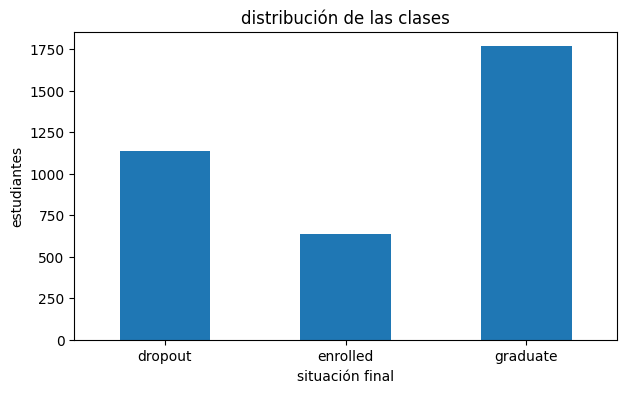

In [5]:
frecuencias = y.value_counts().reindex(clases)
resumen_clases = pd.DataFrame({"estudiantes": frecuencias, "porcentaje": (100 * frecuencias / len(y)).round(2)})
display(resumen_clases)

fig, ax = plt.subplots(figsize=(7, 4))
frecuencias.plot.bar(ax=ax)
ax.set(title="distribución de las clases", xlabel="situación final", ylabel="estudiantes")
ax.tick_params(axis="x", rotation=0)
display(fig)
plt.close(fig)

En la ejecución se observaron 1,137 dropout, 635 enrolled y 1,767 graduate. La clase enrolled es minoritaria. Por eso usamos F1 macro, que pondera por igual el F1 de las tres clases, en lugar de seleccionar el modelo solamente por exactitud.

In [6]:
nominales_uci = {
    "Marital status", "Application mode", "Course", "Daytime/evening attendance",
    "Previous qualification", "Nacionality", "Nationality",
    "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", "Displaced",
    "Educational special needs", "Debtor", "Tuition fees up to date",
    "Gender", "Scholarship holder", "International"
}

def tipos_columnas(datos):
    nominales = [c for c in datos if c in nominales_uci]
    numericas = [c for c in datos if c not in nominales]
    return nominales, numericas

nominales, numericas = tipos_columnas(x)
tabla_tipos = pd.DataFrame({
    "atributo": x.columns,
    "tipo_de_modelado": ["nominal" if c in nominales else "numérico" for c in x.columns],
    "tipo_en_csv": [str(x[c].dtype) for c in x.columns],
    "distintos": [x[c].nunique(dropna=False) for c in x.columns]
})
display(tabla_tipos)

,atributo,tipo_de_modelado,tipo_en_csv,distintos
0,Marital status,nominal,int64,6
1,Application mode,nominal,int64,17
2,Application order,numérico,int64,8
3,Course,nominal,int64,17
4,Daytime/evening attendance,nominal,int64,2
5,Previous qualification,nominal,int64,17
6,Previous qualification (grade),numérico,float64,100
7,Nacionality,nominal,int64,18
8,Mother's qualification,nominal,int64,26
9,Father's qualification,nominal,int64,32


Para las variables, como Course o Application mode, se utiliza codificación one-hot. Los atributos numéricos conservan su significado cuantitativo. Esta separación evita que una categoría con código mayor sea tratada automáticamente como una magnitud mayor.

## 6. Preprocesamiento dentro de pipelines

Definir una sola versión de los preprocesadores y las reglas comunes a todas las evaluaciones. El árbol no necesita estandarización; SVM, regresión logística y kNN sí. Naive Bayes requiere una transformación no negativa para poder comparar sus variantes. Todos se ajustan dentro de los pliegues para no filtrar estadísticas de validación.

Error documentado de las pruebas: kNN devolvió NaN en 18 de 50 configuraciones. El mensaje invalid literal for int() with base 10: dropout se dio en una ruta interna optimizada de scikit-learn al calcular vecinos con etiquetas de texto. Se comprobó que usar algorithm='kd_tree' evita el fallo. Al repetir la búsqueda se obtuvieron 50/50 configuraciones válidas, con F1 macro 0.5769. Conservamos directamente esta solución; no se necesita incluir la celda de error.

In [12]:
def crear_preprocesadores(datos):
    nominales, numericas = tipos_columnas(datos)

    categorias = Pipeline([
        ("relleno", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    def numeros(escala=None):
        pasos = [("relleno", SimpleImputer(strategy="median"))]
        if escala is not None:
            pasos.append(("escala", escala))
        return Pipeline(pasos)

    arbol = ColumnTransformer([
        ("categorias", categorias, nominales),
        ("numeros", numeros(), numericas)
    ])
    escalado = ColumnTransformer([
        ("categorias", categorias, nominales),
        ("numeros", numeros(StandardScaler()), numericas)
    ])
    naive = ColumnTransformer([
        ("categorias", categorias, nominales),
        ("numeros", numeros(MinMaxScaler()), numericas)
    ])
    return arbol, escalado, naive

pre_arbol, pre_escalado, pre_nb = crear_preprocesadores(x)
print("pipelines de preprocesamiento preparados")

pipelines de preprocesamiento preparados


Las variables categóricas se imputan si faltan y se codifican como indicadores. Las continuas se imputan con la mediana; su escalamiento cambia según el clasificador. El flujo es el mismo para entrenamiento y predicción, y el preprocesamiento se vuelve a ajustar dentro de cada pliegue de validación.

## 7. Cinco clasificadores y espacios de búsqueda

Definir los cinco modelos permitidos, sus parámetros principales y RandomizedSearchCV con 50 configuraciones y cinco pliegues. Se declaran criterio, profundidad y poda del árbol; variantes y suavizado de Naive Bayes; k, ponderación y distancia de kNN; kernel, C y gamma del SVM; C y regularización logística; y pesos de clase en árbol, SVM y logística.

In [13]:
def construir_busqueda(nombre, datos, n_iter=50):
    pre_arbol, pre_escalado, pre_nb = crear_preprocesadores(datos)

    if nombre == "árbol de decisión":
        pipeline = Pipeline([
            ("preprocesamiento", pre_arbol),
            ("modelo", DecisionTreeClassifier(random_state=semilla))
        ])
        espacio = {
            "modelo__criterion": ["gini", "entropy", "log_loss"],
            "modelo__max_depth": [None] + list(range(3, 21)),
            "modelo__ccp_alpha": loguniform(1e-5, 5e-2),
            "modelo__min_samples_leaf": randint(1, 21),
            "modelo__class_weight": [None, "balanced"]
        }
    elif nombre == "naive bayes":
        pipeline = Pipeline([
            ("preprocesamiento", pre_nb),
            ("modelo", GaussianNB())
        ])
        espacio = [
            {"modelo": [GaussianNB()], "modelo__var_smoothing": loguniform(1e-12, 1e-6)},
            {"modelo": [MultinomialNB()], "modelo__alpha": loguniform(1e-4, 10)},
            {"modelo": [BernoulliNB()], "modelo__alpha": loguniform(1e-4, 10),
             "modelo__binarize": [0.25, 0.5, 0.75]}
        ]
    elif nombre == "knn":
        pipeline = Pipeline([
            ("preprocesamiento", pre_escalado),
            ("modelo", KNeighborsClassifier(algorithm="kd_tree"))
        ])
        espacio = {
            "modelo__n_neighbors": randint(3, 51),
            "modelo__weights": ["uniform", "distance"],
            "modelo__p": [1, 2],
            "modelo__leaf_size": randint(15, 61)
        }
    elif nombre == "svm":
        pipeline = Pipeline([
            ("preprocesamiento", pre_escalado),
            ("modelo", SVC())
        ])
        espacio = {
            "modelo__kernel": ["linear", "rbf", "poly", "sigmoid"],
            "modelo__C": loguniform(1e-2, 1e3),
            "modelo__gamma": loguniform(1e-5, 1),
            "modelo__degree": [2, 3, 4],
            "modelo__class_weight": [None, "balanced"]
        }
    elif nombre == "regresión logística":
        pipeline = Pipeline([
            ("preprocesamiento", pre_escalado),
            ("modelo", LogisticRegression(solver="saga", max_iter=4000, random_state=semilla))
        ])
        espacio = [
            {"modelo__C": loguniform(1e-3, 1e3), "modelo__penalty": ["l1", "l2"],
             "modelo__class_weight": [None, "balanced"]},
            {"modelo__C": loguniform(1e-3, 1e3), "modelo__penalty": ["elasticnet"],
             "modelo__l1_ratio": [0.25, 0.5, 0.75],
             "modelo__class_weight": [None, "balanced"]}
        ]
    else:
        raise ValueError("clasificador desconocido")

    return RandomizedSearchCV(
        pipeline, espacio, n_iter=n_iter, scoring="f1_macro",
        cv=cv, random_state=semilla, n_jobs=-1,
        refit=True, return_train_score=True, error_score="raise"
    )

nombres_modelos = ["árbol de decisión", "naive bayes", "knn", "svm", "regresión logística"]
print("modelos:", ", ".join(nombres_modelos))
print("configuraciones por modelo:", n_configuraciones)

modelos: árbol de decisión, naive bayes, knn, svm, regresión logística
configuraciones por modelo: 50


Se descartó reducir la búsqueda a dos kernels de SVM solo para ahorrar tiempo. La búsqueda original de SVM tardó unos 900 segundos y la de logística unos 265 segundos. Para kNN quedó fijado kd_tree, la única modificación necesaria para resolver el fallo de predicción con etiquetas de texto. Las 50 configuraciones son un mínimo evaluado, no una garantía de encontrar el óptimo global.

## 8. Búsquedas originales con checkpoints

Recuperar el diccionario busquedas si ya existe. Ejecuta solo los modelos faltantes y guarda los resultados inmediatamente después de cada búsqueda completada. Si Colab se desconecta, al volver a ejecutar no se pierden los modelos que terminaron antes.

In [14]:
busquedas = recuperar("busquedas.joblib", {})
tiempos_busqueda = recuperar("tiempos.joblib", {})

for nombre in nombres_modelos:
    existente = busquedas.get(nombre)
    compatible = False
    if existente is not None:
        try:
            compatible = list(existente.best_estimator_.feature_names_in_) == list(x.columns)
            compatible &= np.isfinite(existente.best_score_)
            compatible &= len(existente.cv_results_["mean_test_score"]) >= 50
            compatible &= np.isfinite(existente.cv_results_["mean_test_score"]).sum() >= 50
        except (AttributeError, ValueError, TypeError):
            compatible = False

    if compatible:
        print(f"{nombre}: recuperado, f1={existente.best_score_:.4f}")
        continue

    print("optimizando:", nombre, flush=True)
    busqueda = construir_busqueda(nombre, x, n_configuraciones)
    inicio = time.perf_counter()
    busqueda.fit(x, y)
    tiempos_busqueda[nombre] = time.perf_counter() - inicio
    busquedas[nombre] = busqueda
    guardar(busquedas, "busquedas.joblib")
    guardar(tiempos_busqueda, "tiempos.joblib")
    print(f"terminó {nombre}: f1={busqueda.best_score_:.4f}")

resumen_busquedas = pd.DataFrame([
    {"modelo": nombre,
     "f1_macro": busquedas[nombre].best_score_,
     "configuraciones_validas": int(np.isfinite(busquedas[nombre].cv_results_["mean_test_score"]).sum()),
     "tiempo_s": tiempos_busqueda.get(nombre, np.nan)}
    for nombre in nombres_modelos
]).sort_values("f1_macro", ascending=False)
display(resumen_busquedas.round(4))

árbol de decisión: recuperado, f1=0.6419
naive bayes: recuperado, f1=0.5890
knn: recuperado, f1=0.5769
svm: recuperado, f1=0.6812
regresión logística: recuperado, f1=0.6805


,modelo,f1_macro,configuraciones_validas,tiempo_s
3,svm,0.6812,50,900.3362
4,regresión logística,0.6805,50,264.8923
0,árbol de decisión,0.6419,50,8.4926
1,naive bayes,0.5890,50,4.9903
2,knn,0.5769,50,216.5584


En la ejecución original, SVM ganó con 0.6812, seguido de regresión logística (0.6805), árbol (0.6419), Naive Bayes (0.5890) y kNN corregido (0.5769). Estos valores son los mejores F1 macro medios de búsqueda. La ventaja entre SVM y logística fue mínima.

## 9. Convergencia de las cinco búsquedas

Muestra cómo evoluciona el mejor F1 macro acumulado tras cada configuración. Durante el desarrollo varias gráficas aparecieron vacías, la primera causa fue la propagación de valores NaN de kNN y también se observó un problema al depender de la figura activa de Matplotlib. Se usa fig, ax = plt.subplots() y presenta esa figura explícitamente. No se conservan ninguna de las celdas gráficas defectuosas.

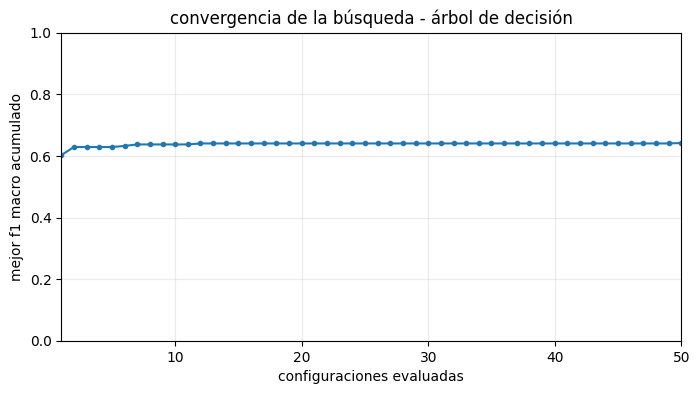

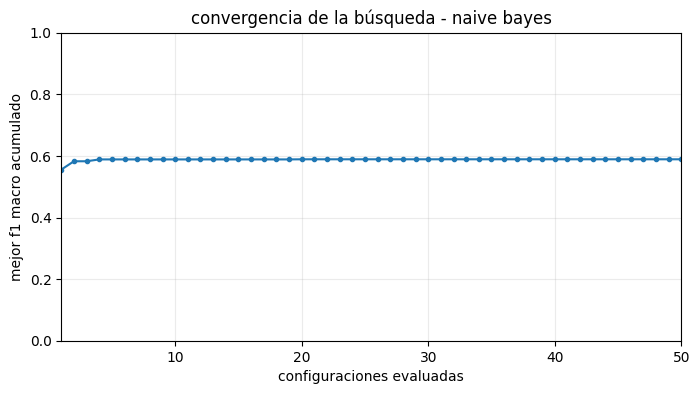

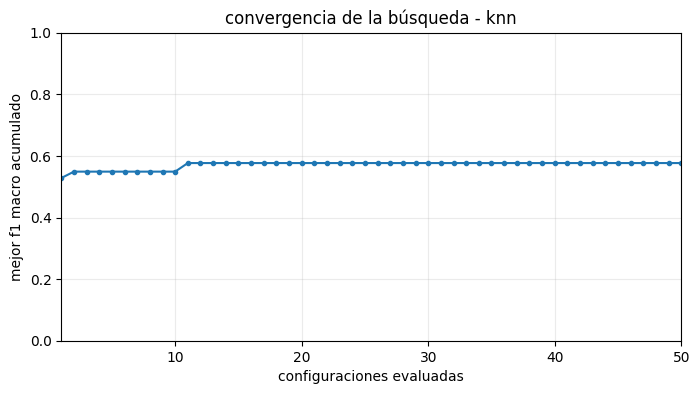

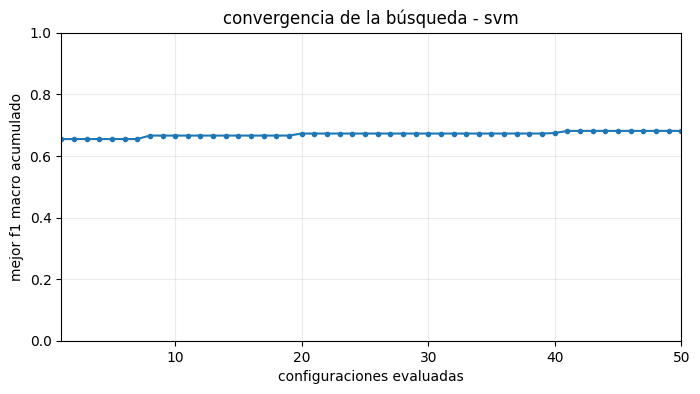

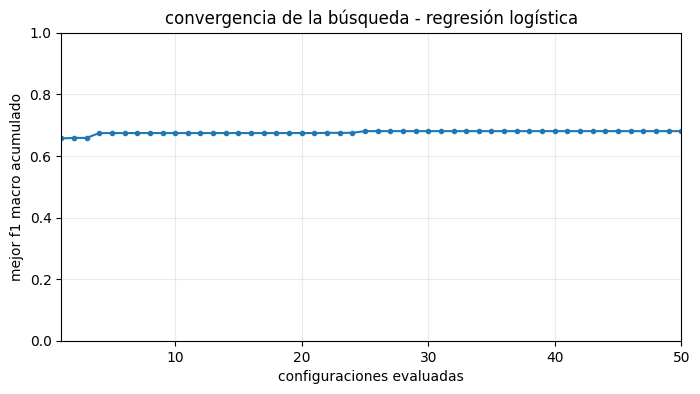

In [15]:
for nombre, busqueda in busquedas.items():
    valores = np.asarray(busqueda.cv_results_["mean_test_score"], dtype=float)
    valores = np.where(np.isfinite(valores), valores, -np.inf)  # ignora intentos inválidos
    mejor_acumulado = np.maximum.accumulate(valores)
    mejor_acumulado[~np.isfinite(mejor_acumulado)] = np.nan

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(np.arange(1, len(valores) + 1), mejor_acumulado, marker="o", markersize=3)
    ax.set(title=f"convergencia de la búsqueda - {nombre}",
           xlabel="configuraciones evaluadas", ylabel="mejor f1 macro acumulado",
           xlim=(1, len(valores)), ylim=(0, 1))
    ax.grid(alpha=0.25)
    display(fig)
    plt.close(fig)

Una curva plana al final sugiere que las últimas configuraciones no mejoraron el mejor F1, aunque no muestra que exista un óptimo global. En kNN corregido se observó una meseta alrededor del intento 11, con F1 0.5769, que se mantuvo hasta la configuración 50. En el resto conviene inspeccionar la curva concreta antes de afirmar que la búsqueda se estabilizó.

## 10. Comparación detallada y métricas por clase

Evaluar cada mejor pipeline en los mismos cinco pliegues y calcula el promedio y desviación estándar del F1 macro. Además, sensibilidad y especificidad de cada clase en formato uno contra el resto.

In [16]:
def sensibilidad_especificidad(reales, predichos, clase):
    bin_real = (np.asarray(reales) == clase).astype(int)
    bin_pred = (np.asarray(predichos) == clase).astype(int)
    tn, fp, fn, tp = confusion_matrix(bin_real, bin_pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else np.nan
    esp = tn / (tn + fp) if tn + fp else np.nan
    return sens, esp

def evaluar_pliegues(modelo, datos, objetivo):
    filas = []
    for numero, (idx_ent, idx_val) in enumerate(cv.split(datos, objetivo), 1):
        candidato = clone(modelo)
        candidato.fit(datos.iloc[idx_ent], objetivo.iloc[idx_ent])
        pred = candidato.predict(datos.iloc[idx_val])
        fila = {"pliegue": numero, "f1_macro": f1_score(objetivo.iloc[idx_val], pred, average="macro")}
        for clase in clases:
            fila[f"sens_{clase}"], fila[f"esp_{clase}"] = sensibilidad_especificidad(objetivo.iloc[idx_val], pred, clase)
        filas.append(fila)
    return pd.DataFrame(filas)

evaluaciones = recuperar("evaluaciones_originales.joblib", {})
for nombre, busqueda in busquedas.items():
    if nombre not in evaluaciones:
        evaluaciones[nombre] = evaluar_pliegues(busqueda.best_estimator_, x, y)
        guardar(evaluaciones, "evaluaciones_originales.joblib")

filas = []
for nombre, evaluacion in evaluaciones.items():
    fila = {"modelo": nombre,
            "f1_macro_media": evaluacion.f1_macro.mean(),
            "f1_macro_std": evaluacion.f1_macro.std(ddof=1),
            "tiempo_busqueda_s": tiempos_busqueda.get(nombre, np.nan)}
    for clase in clases:
        fila[f"sens_{clase}"] = evaluacion[f"sens_{clase}"].mean()
        fila[f"esp_{clase}"] = evaluacion[f"esp_{clase}"].mean()
    filas.append(fila)
comparacion = pd.DataFrame(filas).sort_values("f1_macro_media", ascending=False).reset_index(drop=True)
display(comparacion.round(4))

,modelo,f1_macro_media,f1_macro_std,tiempo_busqueda_s,sens_dropout,esp_dropout,sens_enrolled,esp_enrolled,sens_graduate,esp_graduate
0,svm,0.6812,0.0125,900.3362,0.6693,0.9334,0.5921,0.8165,0.8048,0.8380
1,regresión logística,0.6805,0.0072,264.8923,0.6974,0.9221,0.5685,0.8240,0.7957,0.8414
2,árbol de decisión,0.6419,0.0067,8.4926,0.6464,0.9201,0.5638,0.7724,0.7431,0.8420
3,naive bayes,0.5890,0.0179,4.9903,0.6526,0.8480,0.3606,0.8671,0.7504,0.7229
4,knn,0.5769,0.0088,216.5584,0.6297,0.8768,0.2378,0.9139,0.8517,0.6496


SVM logró F1 macro 0.6812 ± 0.0125; logística, 0.6805 ± 0.0072. Para la clase dropout, logística alcanzó sensibilidad 0.6974 y SVM 0.6693; SVM obtuvo mejor especificidad (0.9334 frente a 0.9221). Enrolled fue la clase más difícil para los cinco modelos. La ligera ventaja del SVM en F1 no demuestra una superioridad en la población de prueba.

## 11. Matriz de confusión y análisis de abandono

Generar predicciones fuera de pliegue del mejor modelo original y su matriz de confusión. Estos valores son interpretables para cada estudiante pero la evaluación sigue compartiendo datos con la selección inicial de hiperparámetros,  no es una validación anidada.

guardado: predicciones_cv_original.joblib


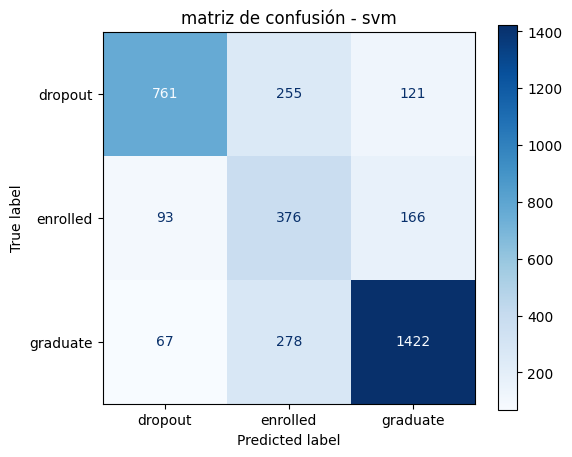

desertores confundidos principalmente con: enrolled
sensibilidad dropout: 0.6693


In [17]:
mejor_original_nombre = comparacion.iloc[0]["modelo"]
mejor_original = busquedas[mejor_original_nombre].best_estimator_
pred_cv_original = recuperar("predicciones_cv_original.joblib")
if pred_cv_original is None or len(pred_cv_original) != len(y):
    pred_cv_original = cross_val_predict(clone(mejor_original), x, y, cv=cv, n_jobs=-1)
    guardar(pred_cv_original, "predicciones_cv_original.joblib")

matriz_original = confusion_matrix(y, pred_cv_original, labels=clases)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matriz_original, display_labels=clases).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title(f"matriz de confusión - {mejor_original_nombre}")
display(fig)
plt.close(fig)

fila_dropout = matriz_original[0].copy()
fila_dropout[0] = 0
print("desertores confundidos principalmente con:", clases[np.argmax(fila_dropout)])
print("sensibilidad dropout:", round(sensibilidad_especificidad(y, pred_cv_original, "dropout")[0], 4))

La matriz de SVM dio 761 desertores identificados correctamente, 255 confundidos con enrolled y 121 con graduate, de 1,137 desertores reales. Por otro lado, reconoció 376/635 inscritos y 1,422/1,767 graduados. La mayor confusión de dropout fue con enrolled, puede ser porque el desempeño temprano de ambos grupos puede ser parecido.

## 12. ¿Conviene esperar al segundo semestre?

Búsqueda de 50 configuraciones con el mismo tipo de clasificador que ganó originalmente, pero añadiendo las seis variables académicas del segundo semestre. No se usa esta versión para producir el CSV final.

In [18]:
busqueda_segundo = recuperar("busqueda_segundo_semestre.joblib")
if busqueda_segundo is None:
    print("optimizando svm con información del segundo semestre...", flush=True)
    inicio = time.perf_counter()
    busqueda_segundo = construir_busqueda(mejor_original_nombre, x_segundo, n_configuraciones)
    busqueda_segundo.fit(x_segundo, y)
    tiempo_segundo = time.perf_counter() - inicio
    guardar(busqueda_segundo, "busqueda_segundo_semestre.joblib")
    guardar(tiempo_segundo, "tiempo_segundo_semestre.joblib")
else:
    tiempo_segundo = recuperar("tiempo_segundo_semestre.joblib", np.nan)

f1_primero = busquedas[mejor_original_nombre].best_score_
f1_segundo = busqueda_segundo.best_score_
print("modelo:", mejor_original_nombre)
print("f1 primer semestre:", round(f1_primero, 4))
print("f1 segundo semestre:", round(f1_segundo, 4))
print("mejora absoluta:", round(f1_segundo - f1_primero, 4))
print("mejora relativa (%):", round(100 * (f1_segundo / f1_primero - 1), 2))

modelo: svm
f1 primer semestre: 0.6812
f1 segundo semestre: 0.7171
mejora absoluta: 0.0359
mejora relativa (%): 5.27


Con SVM se obtuvo 0.6812 al cierre del primer semestre y 0.7171 usando también el segundo: una mejora absoluta de 0.0359 (aprox. 5.27 % relativa). Esperar ayuda a clasificar mejor, pero retrasa la oportunidad de intervenir con estudiantes en riesgo.

## 13. Ingeniería de características del primer semestre

Construir cinco características simples y comprensibles a partir de los conteos académicos: tasas de aprobación, éxito, evaluación, ausencia de evaluación y un indicador que combina calificación y aprobación. Son transformaciones deterministas por estudiante, sin usar estadísticas de otros registros.

Las cinco variables mejoraron el SVM original de 0.6812 a 0.6853, y la regresión logística de 0.6805 a 0.6870. Esa señal motivó la optimización posterior. No se utiliza ninguna columna del segundo semestre en estas características.

In [19]:
def agregar_caracteristicas(datos):
    datos = datos.copy()
    inscritas = datos["Curricular units 1st sem (enrolled)"]
    aprobadas = datos["Curricular units 1st sem (approved)"]
    evaluadas = datos["Curricular units 1st sem (evaluations)"]
    sin_evaluacion = datos["Curricular units 1st sem (without evaluations)"]
    calificacion = datos["Curricular units 1st sem (grade)"]

    datos["tasa_aprobacion"] = aprobadas / inscritas.replace(0, np.nan)
    datos["tasa_exito"] = aprobadas / evaluadas.replace(0, np.nan)
    datos["tasa_evaluacion"] = evaluadas / inscritas.replace(0, np.nan)
    datos["tasa_sin_evaluacion"] = sin_evaluacion / inscritas.replace(0, np.nan)
    datos["rendimiento_ponderado"] = calificacion * datos["tasa_aprobacion"]

    nuevas = ["tasa_aprobacion", "tasa_exito", "tasa_evaluacion",
              "tasa_sin_evaluacion", "rendimiento_ponderado"]
    datos[nuevas] = datos[nuevas].fillna(0)  # resuelve divisiones sin denominador
    return datos

x_mejorado = agregar_caracteristicas(x)
x_prueba_mejorado = agregar_caracteristicas(x_prueba)
assert x_mejorado.columns.tolist() == x_prueba_mejorado.columns.tolist()
print("atributos originales:", x.shape[1], "atributos mejorados:", x_mejorado.shape[1])
display(x_mejorado[["tasa_aprobacion", "tasa_exito", "rendimiento_ponderado"]].head())

atributos originales: 30 atributos mejorados: 35


,tasa_aprobacion,tasa_exito,rendimiento_ponderado
0,1.000000,0.777778,13.312500
1,1.000000,1.000000,12.166667
2,0.400000,0.153846,4.400000
3,0.500000,0.300000,5.833333
4,0.666667,0.307692,7.666667


Un estudiante con tres materias aprobadas de cuatro no tiene el mismo avance que uno con tres aprobadas de ocho. Las tasas permiten expresar esa diferencia. Tasa_evaluacion puede superar 1 si existen varias evaluaciones por materia. Se trata como una razón descriptiva, no como una probabilidad. Cuando el denominador es cero se utiliza 0 como convención para estos indicadores.

## 14. Optimización de los dos finalistas con las nuevas variables

Entrenar SVM y regresión logística con los cinco indicadores anteriores, manteniendo sus 50 configuraciones.

In [20]:
finalistas = {}
archivos_finalistas = {
    "svm mejorado": "svm_mejorado.joblib",
    "regresión logística mejorada": "logistica_mejorada.joblib"
}
for nombre, archivo in archivos_finalistas.items():
    busqueda = recuperar(archivo)
    valido = False
    if busqueda is not None:
        try:
            valido = list(busqueda.best_estimator_.feature_names_in_) == list(x_mejorado.columns)
            valido &= np.isfinite(busqueda.best_score_)
        except (AttributeError, ValueError, TypeError):
            valido = False
    if not valido:
        tipo = "svm" if nombre.startswith("svm") else "regresión logística"
        print("optimizando:", nombre, flush=True)
        busqueda = construir_busqueda(tipo, x_mejorado, n_configuraciones)
        inicio = time.perf_counter()
        busqueda.fit(x_mejorado, y)
        print("tiempo (s):", round(time.perf_counter() - inicio, 1))
        guardar(busqueda, archivo)
    finalistas[nombre] = busqueda

resumen_finalistas = pd.DataFrame([
    {"modelo": nombre, "f1_macro": b.best_score_, "mejores_parametros": str(b.best_params_)}
    for nombre, b in finalistas.items()
]).sort_values("f1_macro", ascending=False)
display(resumen_finalistas)

,modelo,f1_macro,mejores_parametros
1,regresión logística mejorada,0.687006,"{'modelo__C': np.float64(0.13820379228637), 'm..."
0,svm mejorado,0.685315,"{'modelo__C': np.float64(14.851035064938554), ..."


El SVM mejorado consiguió 0.6853 con kernel RBF, C≈14.851, gamma≈0.004515 y pesos balanced. La logística mejorada consiguió 0.6870, con C≈0.1382, regularización elasticnet, l1_ratio=0.25 y pesos balanced. Los mejores parámetros fueron iguales a los del primer experimento de cada modelo. La mejora se asoció a las características nuevas. La ventaja de logística es pequeña y no es suficiente para asegurar superioridad fuera de muestra.

## 15. Experimentos descartados y decisiones

Durante el desarrollo también se probaron pesos personalizados para SVM. El mayor F1 observado fue 0.6862 con pesos `{'dropout': 1, 'enrolled': 2, 'graduate': 1}`, frente a 0.6853 con balanced. Se descartó usar esos pesos en el modelo final porque la ganancia fue de apenas 0.0009, se obtuvo después de probar varias opciones sobre los mismos pliegues y no constituye evidencia de mejor generalización.

También se descartó comparar los modelos por un único máximo de búsqueda o cambiar a un clasificador más complejo no permitido. Los siguientes apartados comparan los dos modelos mejorados con validación repetida y validación anidada y documentan claramente sus limitaciones.

## 16. Validación cruzada repetida de finalistas

Evaluar ambos finalistas usando 5 pliegues x 3 repeticiones, y guarda sus puntuaciones. No reajusta sus hiperparámetros, estos siguen siendo los seleccionados antes.

In [21]:
repetida = recuperar("validacion_repetida_finalistas.joblib", {})
cv_repetida = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=123)

for nombre, busqueda in finalistas.items():
    if nombre not in repetida or len(repetida[nombre]) != 15:
        print("evaluando:", nombre, flush=True)
        puntajes = cross_val_score(clone(busqueda.best_estimator_), x_mejorado, y,
                                   cv=cv_repetida, scoring="f1_macro", n_jobs=2,
                                   error_score="raise")
        repetida[nombre] = puntajes
        guardar(repetida, "validacion_repetida_finalistas.joblib")

comparacion_repetida = pd.DataFrame([
    {"modelo": nombre, "f1_medio": np.mean(puntajes), "desviacion": np.std(puntajes, ddof=1),
     "minimo": np.min(puntajes), "maximo": np.max(puntajes)}
    for nombre, puntajes in repetida.items()
]).sort_values("f1_medio", ascending=False)
display(comparacion_repetida.round(4))

evaluando: svm mejorado
guardado: validacion_repetida_finalistas.joblib
evaluando: regresión logística mejorada
guardado: validacion_repetida_finalistas.joblib


,modelo,f1_medio,desviacion,minimo,maximo
0,svm mejorado,0.6858,0.0152,0.6595,0.7087
1,regresión logística mejorada,0.6851,0.0110,0.6732,0.7076


En la ejecución anterior, el SVM mejorado obtuvo 0.6858 ± 0.0152 y la regresión logística 0.6851 ± 0.0110. La diferencia de 0.0007 es prácticamente un empate, la regresión logística tuvo menor dispersión. No es correcto afirmar superioridad estadística con estos números ni interpretar los 15 resultados como independientes.

## 17. Evaluación adicional y selección de los modelos finalistas

En cada uno de los cinco pliegues externos, realiza una nueva búsqueda de 50 configuraciones con cinco pliegues internos y evalúa una sola vez en el pliegue externo reservado. Así los datos externos no participan en la selección de hiperparámetros. Se utilizan los mismos pliegues externos para SVM y logística.

Logística obtuvo 0.6868 ± 0.0134, con resultados [0.6939, 0.7002, 0.6935, 0.6792, 0.6673]. Se guardó como validacion_anidada_logistica.joblib.


In [31]:
if resultado_anidado is not None:

    puntajes_logistica = np.asarray(
        resultado_anidado["f1_por_pliegue"],
        dtype=float
    )

    print("validación anidada de regresión logística")
    print("f1 macro:", round(puntajes_logistica.mean(), 4))
    print("desviación:", round(puntajes_logistica.std(ddof=1), 4))
    print("f1 por pliegue:", np.round(puntajes_logistica, 4))

else:
    print("no se encontraron resultados de validación anidada")

validación anidada de regresión logística
f1 macro: 0.6868
desviación: 0.0134
f1 por pliegue: [0.6939 0.7002 0.6935 0.6792 0.6673]


Se realizó una validación cruzada anidada de cinco pliegues para la regresión logística mejorada. Se obtuvo un F1 macro promedio de 0.6868, con una desviación estándar de 0.0134.

Este resultado sugiere que el modelo mantiene un desempeño similar cuando los hiperparámetros se seleccionan dentro de cada partición de entrenamiento.

También se consideró realizar la misma evaluación para SVM. Sin embargo, debido a su elevado costo computacional, se decidió no incluirla como parte de la evaluación final.

Para comparar ambos clasificadores se utilizaron los resultados de la validación cruzada estratificada repetida ya que este procedimiento se aplicó a los dos modelos bajo las mismas condiciones.

En esa comparación, SVM obtuvo un F1 macro de 0.6858 y regresión logística alcanzó 0.6851. Aunque SVM presentó un resultado ligeramente superior, la diferencia es demasiado pequeña para afirmar que uno de los dos modelos sea claramente mejor.

## 18. Selección del modelo final y generación de predicciones

Se selecciona el clasificador que se utilizan para predecir la situación académica de los 885 estudiantes del conjunto de prueba.

Durante los experimentos anteriores, SVM y regresión logística fueron los modelos que obtuvieron mejores resultados. Después de incorporar cinco características relacionadas con el rendimiento académico del primer semestre, ambos mejoraron su F1 macro.

Para tomar la decisión final, se consideran los resultados de la validación cruzada estratificada repetida, donde SVM obtuvo un F1 macro promedio de 0.6858, mientras que regresión logística alcanzó 0.6851. Aunque la diferencia es pequeña y no demuestra que SVM sea estadísticamente superior, se seleccionó porque obtuvo el mayor valor de la métrica principal bajo el mismo procedimiento de evaluación.



In [36]:
# 18. selección del modelo final y generación de predicciones

import joblib
import pandas as pd
from pathlib import Path

# carpeta opcional para recuperar modelos
carpeta_modelos = Path("/content/drive/MyDrive/practica_desercion")

# recuperar o entrenar svm mejorado
ruta_svm = carpeta_modelos / "svm_mejorado.joblib"

if ruta_svm.exists():

    print("recuperando svm desde drive...")
    svm_mejorado = joblib.load(ruta_svm)

else:

    print("entrenando svm desde cero...")

    svm_mejorado = construir_busqueda(
        "svm",
        x_mejorado,
        n_iter=50
    )

    svm_mejorado.fit(x_mejorado, y)

# recuperar o entrenar regresión logística
ruta_logistica = carpeta_modelos / "logistica_mejorada.joblib"

if ruta_logistica.exists():

    print("recuperando regresión logística desde drive...")
    logistica_mejorada = joblib.load(ruta_logistica)

else:

    print("entrenando regresión logística desde cero...")

    logistica_mejorada = construir_busqueda(
        "regresión logística",
        x_mejorado,
        n_iter=50
    )

    logistica_mejorada.fit(x_mejorado, y)

# seleccionar el modelo según la validación repetida
puntuaciones = {
    "svm mejorado": 0.6858,
    "regresión logística mejorada": 0.6851
}

modelo_elegido = max(puntuaciones, key=puntuaciones.get)

if modelo_elegido == "svm mejorado":
    modelo_final = svm_mejorado.best_estimator_
else:
    modelo_final = logistica_mejorada.best_estimator_

# generar predicciones
pred_final = modelo_final.predict(x_prueba_mejorado)

predicciones = pd.DataFrame({
    "id": prueba["id"].to_numpy(),
    "Target": pd.Series(pred_final).astype(str).str.lower()
})

# verificar el archivo
assert predicciones.shape == (885, 2)
assert predicciones.columns.tolist() == ["id", "Target"]
assert predicciones["id"].is_unique
assert predicciones["Target"].isin(
    ["dropout", "enrolled", "graduate"]
).all()
assert not predicciones.isna().any().any()

# guardar archivo local
predicciones.to_csv("predicciones.csv", index=False)

# guardar copia en drive cuando esté disponible
if carpeta_modelos.exists():
    predicciones.to_csv(
        carpeta_modelos / "predicciones.csv",
        index=False
    )

print("modelo seleccionado:", modelo_elegido)
print("archivo generado:", predicciones.shape)

display(predicciones.head())

recuperando svm desde drive...
recuperando regresión logística desde drive...
modelo seleccionado: svm mejorado
archivo generado: (885, 2)


,id,Target
0,6,graduate
1,12,graduate
2,15,graduate
3,18,enrolled
4,19,graduate


Se seleccionó el SVM mejorado como clasificador final. Este modelo utiliza las características originales del primer semestre junto con cinco variables adicionales que describen el desempeño académico, como la tasa de aprobación y la proporción de materias evaluadas.

En la validación cruzada repetida obtuvo un F1 macro promedio de 0.6858, ligeramente superior al 0.6851 de regresión logística. Sin embargo, la diferencia es pequeña, por lo que no podemos asegurar que SVM tenga un mejor desempeño sobre estudiantes nuevos.

Con el modelo seleccionado se generaron las predicciones de los 885 estudiantes del conjunto de prueba. Se conservaron los identificadores originales y se verificó que las etiquetas producidas correspondieran a las tres categorías solicitadas.

### Conclusiones

Después de incorporar las nuevas características académicas, SVM y regresión logística presentaron mejoras respecto a sus versiones originales.

Para comparar ambos modelos se utilizó una validación cruzada estratificada de cinco pliegues repetida tres veces. SVM obtuvo un F1 macro promedio de 0.6858, mientras que regresión logística alcanzó 0.6851.

Aunque la diferencia fue pequeña, se seleccionó SVM como clasificador final por presentar el mayor F1 macro promedio bajo este procedimiento. Esta decisión no implica que su superioridad estadística esté demostrada.

Se realizó también una validación cruzada anidada para regresión logística, con un F1 macro de 0.6868. Se consideró realizar una evaluación equivalente para SVM, pero se descartó debido al tiempo de procesamiento requerido.

El SVM mejorado se utilizó para generar las predicciones de los 885 estudiantes de prueba, se utilizó solo la información disponible al cierre del primer semestre.

**Declaración sobre el uso de inteligencia artificial**

Para la realización de esta práctica se utilizó *ChatGPT* como herramienta de soporte técnico, pedagógico y de redacción.
Alcance de uso:
* Soporte de código y resolución de errores
* Supervisión de formato de texto.

